# VAE and RealNVP comparison
This notebook evaluates saved predictions from three seeds per model.
Both models used the same synthetic dataset and validation threshold rule.

Output zip from 03b_realnvp is needed to upload here

In [1]:
from pathlib import Path
import zipfile
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    PrecisionRecallDisplay,
)

project = Path("/content/transaction_comparison")
project.mkdir(parents=True, exist_ok=True)

uploaded = files.upload()
zip_names = [
    name for name in uploaded
    if name.lower().endswith(".zip")
]
assert len(zip_names) == 1, "Upload the combined backup ZIP."

with zipfile.ZipFile(zip_names[0]) as archive:
    for name in archive.namelist():
        destination = (project / name).resolve()
        assert destination.is_relative_to(project.resolve())
    archive.extractall(project)

del uploaded

evaluation = project / "evaluation"
evaluation.mkdir(exist_ok=True)

with open(project / "data/dataset_config.json") as file:
    config = json.load(file)

test = pd.read_csv(project / "data/test.csv")
seeds = config["model_seeds"]

print("Test transactions:", len(test))
print("Seeds:", seeds)
print("Ready to evaluate saved predictions.")

Saving pair3_both_models_backup.zip to pair3_both_models_backup.zip
Test transactions: 2000
Seeds: [42, 123, 2026]
Ready to evaluate saved predictions.


In [2]:
prediction_tables = []
metric_records = []
subtype_records = []

for model, prefix in [("VAE", "vae"), ("RealNVP", "realnvp")]:
    for seed in seeds:
        table = pd.read_csv(
            project / f"outputs/{prefix}_test_seed{seed}.csv"
        )

        assert table["transaction_id"].is_unique
        assert set(table["transaction_id"]) == set(test["transaction_id"])

        # Match the original transaction order
        table = table.set_index("transaction_id").loc[
            test["transaction_id"]
        ].reset_index()

        assert np.array_equal(table["label"], test["label"])
        assert np.array_equal(
            table["anomaly_type"], test["anomaly_type"]
        )
        assert np.isfinite(table["anomaly_score"]).all()
        assert table["predicted_unusual"].isin([0, 1]).all()

        with np.load(project / "data/shared_arrays.npz") as arrays:
            assert np.array_equal(test["label"], arrays["y_test"])

        training = pd.read_csv(
            project / f"results/{prefix}_training_summary.csv"
        )
        threshold = float(
            training.set_index("seed").loc[seed, "threshold"]
        )

        assert np.array_equal(
            table["predicted_unusual"],
            (table["anomaly_score"] > threshold).astype(int),
        )

        y = table["label"]
        predicted = table["predicted_unusual"]
        scores = table["anomaly_score"]

        tn, fp, fn, tp = confusion_matrix(
            y, predicted, labels=[0, 1]
        ).ravel()

        metric_records.append({
            "model": model,
            "seed": seed,
            "roc_auc": roc_auc_score(y, scores),
            "average_precision": average_precision_score(y, scores),
            "precision": precision_score(
                y, predicted, zero_division=0
            ),
            "recall": recall_score(y, predicted, zero_division=0),
            "f1": f1_score(y, predicted, zero_division=0),
            "false_positive_rate": fp / (fp + tn),
            "false_alerts": int(fp),
            "missed_unusual": int(fn),
            "total_alerts": int(fp + tp),
        })

        for subtype, group in table[table["label"] == 1].groupby(
            "anomaly_type"
        ):
            detected = int(group["predicted_unusual"].sum())

            subtype_records.append({
                "model": model,
                "seed": seed,
                "anomaly_type": subtype,
                "transactions": len(group),
                "detected": detected,
                "missed": len(group) - detected,
                "recall": detected / len(group),
            })

        table["model"] = model
        table["seed"] = seed
        prediction_tables.append(table)

predictions = pd.concat(prediction_tables, ignore_index=True)
metrics = pd.DataFrame(metric_records)
subtypes = pd.DataFrame(subtype_records)

summary_fields = [
    "roc_auc", "average_precision", "precision", "recall",
    "f1", "false_positive_rate", "false_alerts",
    "missed_unusual", "total_alerts",
]

summary = metrics.groupby("model")[summary_fields].agg(
    ["mean", "std"]
)
summary.columns = [
    f"{metric}_{stat}" for metric, stat in summary.columns
]

subtype_summary = subtypes.groupby(
    ["model", "anomaly_type"]
).agg(
    transactions_per_seed=("transactions", "first"),
    mean_recall=("recall", "mean"),
    std_recall=("recall", "std"),
    mean_missed=("missed", "mean"),
)

metrics.to_csv(evaluation / "verified_metrics.csv", index=False)
summary.to_csv(evaluation / "model_summary.csv")
subtypes.to_csv(evaluation / "subtype_results.csv", index=False)
subtype_summary.to_csv(evaluation / "subtype_summary.csv")

display(summary.round(4))
display(subtype_summary.round(4))
print("All six prediction files verified.")

,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,false_positive_rate_mean,false_positive_rate_std,false_alerts_mean,false_alerts_std,missed_unusual_mean,missed_unusual_std,total_alerts_mean,total_alerts_std
model,,,,,,,,,,,,,,,,,,
RealNVP,0.9940,0.0043,0.9703,0.0229,0.6853,0.0179,0.9633,0.0257,0.8006,0.0111,0.0493,0.0050,88.6667,8.9629,7.3333,5.1316,281.3333,13.0512
VAE,0.9911,0.0020,0.9468,0.0093,0.7120,0.0287,0.9433,0.0104,0.8112,0.0155,0.0426,0.0065,76.6667,11.7189,11.3333,2.0817,265.3333,13.6504


transactions_per_seed  mean_recall  \
model   anomaly_type                                                      
RealNVP large_discount                                  67       1.0000   
        large_quantity                                  67       0.9254   
        short_duration_for_quantity                     66       0.9646   
VAE     large_discount                                  67       1.0000   
        large_quantity                                  67       0.8308   
        short_duration_for_quantity                     66       1.0000   

                                     std_recall  mean_missed  
model   anomaly_type                                          
RealNVP large_discount                   0.0000       0.0000  
        large_quantity                   0.0259       5.0000  
        short_duration_for_quantity      0.0612       2.3333  
VAE     large_discount                   0.0000       0.0000  
        large_quantity                   0.0311      11.3333  
        short_duration_for_quantity      0.0000       0.0000

All six prediction files verified.


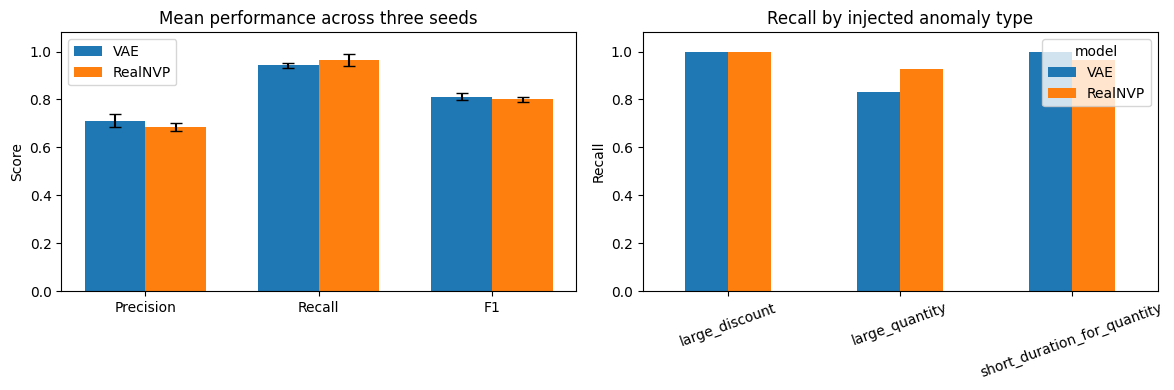

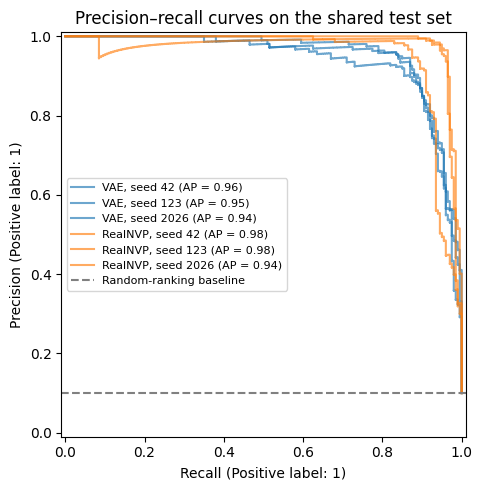

In [3]:
models = ["VAE", "RealNVP"]
colours = ["tab:blue", "tab:orange"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

plot_fields = ["precision", "recall", "f1"]
x = np.arange(len(plot_fields))
width = 0.35

for i, model in enumerate(models):
    group = metrics[metrics["model"] == model]

    axes[0].bar(
        x + (i - 0.5) * width,
        group[plot_fields].mean(),
        width,
        yerr=group[plot_fields].std(),
        capsize=4,
        label=model,
        color=colours[i],
    )

axes[0].set_xticks(x, ["Precision", "Recall", "F1"])
axes[0].set_ylim(0, 1.08)
axes[0].set_title("Mean performance across three seeds")
axes[0].set_ylabel("Score")
axes[0].legend()

recall_table = subtype_summary["mean_recall"].unstack("model")
recall_table[models].plot.bar(
    ax=axes[1], color=colours, rot=20
)
axes[1].set_ylim(0, 1.08)
axes[1].set_title("Recall by injected anomaly type")
axes[1].set_ylabel("Recall")
axes[1].set_xlabel("")

fig.tight_layout()
fig.savefig(
    evaluation / "performance_comparison.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

# Show every seed rather than selecting the best
fig, ax = plt.subplots(figsize=(7, 5))

for model, colour in zip(models, colours):
    for seed in seeds:
        group = predictions[
            (predictions["model"] == model)
            & (predictions["seed"] == seed)
        ]

        PrecisionRecallDisplay.from_predictions(
            group["label"],
            group["anomaly_score"],
            name=f"{model}, seed {seed}",
            ax=ax,
            color=colour,
            alpha=0.65,
        )

ax.axhline(
    test["label"].mean(),
    color="grey",
    linestyle="--",
    label="Random-ranking baseline",
)
ax.set_title("Precision–recall curves on the shared test set")
ax.legend(fontsize=8)

fig.tight_layout()
fig.savefig(
    evaluation / "precision_recall_curves.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

### Conclusion and limitations

RealNVP detected more unusual transactions, particularly large-quantity
cases. The VAE generated fewer false alarms and had better precision.
and F1 at the fixed validation threshold.

The VAE is the better choice when the focus is on reviewing workloads.
RealNVP is worth considering when it's more important to catch unusual transactions.
costly. Any operational choice requires real-data validation.

Both models found all the large-discount anomalies that were added, indicating.
This type of anomaly was simple to handle with the selected generator. Results are
limited to one synthetic dataset and three training seeds.


In [4]:
import shutil
from google.colab import files

backup = shutil.make_archive(
    "/content/pair3_evaluated_backup",
    "zip",
    root_dir=str(project),
)

files.download(backup)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>